# 08 — LSTM for Level 1 sales

This notebook trains a two-layer LSTM to predict all 28 future daily sales
values from a window of observed sales. A linear head maps the last recurrent
state to 28 outputs. The input contains one channel, Level 1 sales, so the
experiment measures a history-only LSTM. The tabular models in notebooks 06–07
also consider calendar, events and SNAP inputs.

Use the same processed Kaggle dataset and run on CPU. The notebook reads
Train and Validation, uses the existing three forecast origins and keeps the
same baselines and score definitions.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib import metadata
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
import hashlib
import json
import platform
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

DATA_DIR = None
OUTPUT_DIR = None
HORIZON = 28
ORIGINS = (1829, 1857, 1885)
SEASON_LENGTH = 7
MA_WINDOWS = (7, 28)
LOOKBACKS = (28, 56)
HIDDEN_SIZES = (16, 32)
LOSSES = ('mse', 'huber')
PRIMARY_SEED = 42
SENSITIVITY_SEEDS = (123, 2026)
BATCH_SIZE = 256
LAYERS = 2
DROPOUT = 0.20
LEARNING_RATE = 0.003
LR_STEP = 15
LR_GAMMA = 0.5
HUBER_DELTA = 0.05
MAX_EPOCHS = 40
PATIENCE = 8
CPU_THREADS = 2
RUN_STARTED = perf_counter()

torch.set_num_threads(CPU_THREADS)
torch.use_deterministic_algorithms(True)
print(f'PyTorch {torch.__version__} | CPU threads {CPU_THREADS}')

PyTorch 2.11.0+cpu | CPU threads 2


## Data and scoring

The dataset fingerprints, forecast dates, scoring and seasonal baselines
follow the previous notebooks.

In [2]:
FILENAMES = ('train.csv', 'val.csv')


def find_data_directory(override=None):
    if override is not None:
        selected = Path(override).expanduser().resolve()
        if not all((selected / name).is_file() for name in FILENAMES):
            raise FileNotFoundError(f'Expected train.csv and val.csv in: {selected}')
        return selected

    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if all((directory / name).is_file() for name in FILENAMES):
            candidates.add(directory.resolve())

    root = Path('/kaggle/input')
    if root.is_dir():
        for path in root.rglob('train.csv'):
            if all((path.parent / name).is_file() for name in FILENAMES):
                candidates.add(path.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            'Attach the processed Kaggle dataset containing train.csv and val.csv, '
            'or set DATA_DIR explicitly.'
        )
    if len(candidates) > 1:
        options = '\n'.join(str(path) for path in sorted(candidates))
        raise ValueError(f'Multiple datasets found. Set DATA_DIR explicitly:\n{options}')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'lstm_output'
)
print(f'Data: {data_dir}')
print(f'Output: {output_dir.resolve()}')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Output: /kaggle/working


In [3]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
NUMERIC_COLUMNS = ['total_sales', 'wday_iso', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']
EVENT_COLUMNS = ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']
REFERENCE_SHA256 = {'train': 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271', 'val': 'fbee2683fca3c5fc731b1d81829a56aa12c71e5b70ad124a1ac01ab3754536b5'}
SPLIT_DAYS = {'train': (1, 1885), 'val': (1886, 1913)}
FIRST_DATE = pd.Timestamp('2011-01-29')


def require(condition, message):
    if not condition:
        raise ValueError(message)


def table_sha256(frame):
    canonical_csv = frame[EXPECTED_COLUMNS].to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()


def validate_split(name, directory):
    path = directory / f'{name}.csv'
    frame = pd.read_csv(path, keep_default_na=False)
    require(list(frame.columns) == EXPECTED_COLUMNS,
            f'{name}: columns or column order differ from the audited dataset.')

    first, last = SPLIT_DAYS[name]
    require(len(frame) == last - first + 1, f'{name}: incorrect row count.')
    require(frame['d'].tolist() == [f'd_{day}' for day in range(first, last + 1)],
            f'{name}: day IDs are missing, duplicated, or out of order.')
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    expected_dates = pd.date_range(FIRST_DATE + pd.Timedelta(days=first - 1),
                                   periods=len(frame), freq='D')
    require(pd.DatetimeIndex(dates).equals(expected_dates),
            f'{name}: dates do not match the fixed chronological split.')
    require(not frame.duplicated(['d']).any() and not dates.duplicated().any(),
            f'{name}: duplicate day or date.')
    frame['date'] = dates.dt.strftime('%Y-%m-%d')

    for column in NUMERIC_COLUMNS:
        values = pd.to_numeric(frame[column], errors='raise')
        require(bool(np.isfinite(values.to_numpy()).all()),
                f'{name}: {column} contains missing or non-finite values.')
        require(bool((values % 1 == 0).all()), f'{name}: {column} must contain integers.')
        frame[column] = values.astype(np.int64)

    require(bool((frame['total_sales'] >= 0).all()), f'{name}: negative sales.')
    require(np.array_equal(frame['wday_iso'], dates.dt.dayofweek + 1),
            f'{name}: incorrect ISO weekday (Monday=1).')
    require(np.array_equal(frame['month'], dates.dt.month), f'{name}: incorrect month.')
    require(np.array_equal(frame['year'], dates.dt.year), f'{name}: incorrect year.')
    require(frame['weekday'].tolist() == dates.dt.day_name().tolist(),
            f'{name}: incorrect weekday names.')
    for column in ['snap_CA', 'snap_TX', 'snap_WI']:
        require(bool(frame[column].isin([0, 1]).all()), f'{name}: {column} is not binary.')
    for column in EVENT_COLUMNS:
        require(bool(frame[column].map(lambda value: isinstance(value, str)
                     and bool(value.strip())).all()),
                f'{name}: empty event labels; expected the literal string None.')

    fingerprint = table_sha256(frame)
    require(fingerprint == REFERENCE_SHA256[name],
            f'{name}: table values differ from the audited handoff. '
            'Use the audited original processed CSV files.')
    inventory = {
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'first_day': frame['d'].iloc[0],
        'last_day': frame['d'].iloc[-1],
        'first_date': frame['date'].iloc[0],
        'last_date': frame['date'].iloc[-1],
        'table_sha256': fingerprint,
        'matches_audited_handoff': True,
    }
    return frame, inventory

In [4]:
frames = {}
input_inventory = []
for split in SPLIT_DAYS:
    frames[split], record = validate_split(split, data_dir)
    input_inventory.append(record)

development = pd.concat([frames['train'], frames['val']], ignore_index=True)
require(len(development) == 1913, 'Expected exactly 1,913 development days.')
require(development['d'].tolist() == [f'd_{day}' for day in range(1, 1914)],
        'Development data must be consecutive and end at d_1913.')
development['date'] = pd.to_datetime(development['date'])

fold_plan = pd.DataFrame([
    {
        'fold': fold,
        'origin_day': f'd_{origin}',
        'origin_date': development.iloc[origin - 1]['date'].strftime('%Y-%m-%d'),
        'history_rows': origin,
        'forecast_start': development.iloc[origin]['date'].strftime('%Y-%m-%d'),
        'forecast_end': development.iloc[origin + HORIZON - 1]['date'].strftime('%Y-%m-%d'),
    }
    for fold, origin in enumerate(ORIGINS, start=1)
])
print(pd.DataFrame(input_inventory)[['file', 'rows', 'columns',
                                    'matches_audited_handoff']].to_string(index=False))
print(fold_plan.to_string(index=False))
print('PASS: development data verified; test.csv has not been read.')

     file  rows  columns  matches_audited_handoff
train.csv  1885       14                     True
  val.csv    28       14                     True
 fold origin_day origin_date  history_rows forecast_start forecast_end
    1     d_1829  2016-01-31          1829     2016-02-01   2016-02-28
    2     d_1857  2016-02-28          1857     2016-02-29   2016-03-27
    3     d_1885  2016-03-27          1885     2016-03-28   2016-04-24
PASS: development data verified; test.csv has not been read.


In [5]:
CONFIGS = [
    {'model': 'Naive', 'config_id': 'naive', 'window': 0, 'season_length': 0},
    {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7',
     'window': 0, 'season_length': SEASON_LENGTH},
] + [
    {'model': 'Moving Average', 'config_id': f'moving_average_{window}',
     'window': window, 'season_length': 0}
    for window in MA_WINDOWS
]


def predict_baseline(history, config, horizon=HORIZON):
    """Return a fixed-origin forecast using observed history only."""
    history = np.asarray(history, dtype=np.float64)
    require(history.ndim == 1 and len(history) >= 2,
            'History must be a one-dimensional series with at least two observations.')
    require(np.isfinite(history).all(), 'History must contain finite values.')
    require(horizon > 0, 'Forecast horizon must be positive.')

    if config['model'] == 'Naive':
        prediction = np.full(horizon, history[-1], dtype=np.float64)
    elif config['model'] == 'Seasonal Naive':
        period = config['season_length']
        require(0 < period <= len(history), 'Invalid seasonal period.')
        prediction = np.tile(history[-period:], int(np.ceil(horizon / period)))[:horizon]
    elif config['model'] == 'Moving Average':
        window = config['window']
        require(0 < window <= len(history), 'Invalid averaging window.')
        prediction = np.full(horizon, history[-window:].mean(), dtype=np.float64)
    else:
        raise ValueError(f'Unknown model: {config["model"]}')

    require(prediction.shape == (horizon,) and np.isfinite(prediction).all(),
            'The forecast must contain exactly one finite value per target day.')
    clipped_count = int((prediction < 0).sum())
    return np.maximum(prediction, 0.0), clipped_count


def score_forecast(actual, prediction, history):
    actual = np.asarray(actual, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    history = np.asarray(history, dtype=np.float64)
    require(actual.shape == prediction.shape == (HORIZON,),
            'Each evaluation block must contain exactly 28 actuals and forecasts.')
    require(np.isfinite(actual).all() and np.isfinite(prediction).all(),
            'Scoring inputs must be finite.')
    require(history.ndim == 1 and len(history) >= 2 and np.isfinite(history).all(),
            'The RMSSE history must be a finite one-dimensional prefix.')
    scale = float(np.mean(np.diff(history) ** 2))
    require(np.isfinite(scale) and scale > 0, 'The RMSSE denominator must be positive.')
    error = actual - prediction
    mse = float(np.mean(error ** 2))
    return {
        'rmsse': float(np.sqrt(mse / scale)),
        'mae': float(np.mean(np.abs(error))),
        'rmse': float(np.sqrt(mse)),
        'rmsse_scale': scale,
    }

## Sequence construction and epoch selection

Each supervised example ends its input at an observed day and uses the next
28 days as its target vector. Each training target vector ends inside the
corresponding fitting prefix. A forecast uses the most recent 28 or 56 observed
days at its origin. The output is issued in one step.

For each outer origin, reserve the final 28 observed days inside that origin
as an inner monitoring block. Fit MinMax on the prefix before that block,
train with Adam and batch size 256, and monitor inner RMSE in sales units.
Stop after eight epochs without improvement, up to 40 epochs. Reinitialize
the model with the same seed, fit a new MinMax on the full observed prefix
and train for exactly the selected number of epochs. Adam starts at 0.003 and
halves its learning rate every 15 epochs during both stages. MSE and Huber
operate on MinMax-scaled targets. The Huber threshold is 0.05 on that scale.

The eight combinations of lookback, hidden width and loss are ranked by
RMSSE on the designated outer Validation window at origin d_1885. The selected
configuration is checked at the two earlier origins with their own inner
epoch selection. The three folds summarize retrospective development behavior.
Seed 42 is the main run. Seeds 123 and 2026 repeat the selected configuration
on Validation to describe sensitivity to initialization and batch order.

In [6]:
LSTM_CONFIGS = [
    {'config_id': f'lstm_w{window}_h{width}_{loss}', 'lookback': window,
     'hidden_size': width, 'loss': loss}
    for window in LOOKBACKS for width in HIDDEN_SIZES for loss in LOSSES
]


class SalesLSTM(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.recurrent = nn.LSTM(
            input_size=1, hidden_size=hidden_size, num_layers=LAYERS,
            dropout=DROPOUT, batch_first=True,
        )
        self.head = nn.Linear(hidden_size, HORIZON)

    def forward(self, sequence):
        _, (hidden, _) = self.recurrent(sequence)
        return self.head(hidden[-1])


def prepare_examples(prefix, lookback):
    sales = np.asarray(prefix, dtype=np.float64)
    require(sales.ndim == 1 and np.isfinite(sales).all(), 'Invalid observed prefix.')
    require(len(sales) >= lookback + HORIZON, 'Prefix too short for LSTM training.')
    minimum, maximum = float(sales.min()), float(sales.max())
    span = maximum - minimum
    require(span > 0, 'MinMax requires variation in observed sales.')
    scaled = ((sales - minimum) / span).astype(np.float32)
    blocks = np.lib.stride_tricks.sliding_window_view(scaled, lookback + HORIZON)
    x = torch.from_numpy(blocks[:, :lookback, None].copy())
    y = torch.from_numpy(blocks[:, lookback:].copy())
    require(x.shape == (len(sales)-lookback-HORIZON+1, lookback, 1),
            'Training windows have an unexpected shape.')
    require(y.shape == (len(x), HORIZON), 'Target shape differs from the 28-day design.')
    return x, y, {'min': minimum, 'max': maximum}


def predict_sales(model, prefix, lookback, scale):
    recent = np.asarray(prefix[-lookback:], dtype=np.float64)
    require(recent.shape == (lookback,), 'Forecast requires a complete observed window.')
    span = scale['max'] - scale['min']
    sequence = torch.tensor((recent-scale['min'])/span, dtype=torch.float32).reshape(1, lookback, 1)
    model.eval()
    with torch.inference_mode():
        forecast = model(sequence).squeeze(0).numpy().astype(np.float64) * span + scale['min']
    require(forecast.shape == (HORIZON,) and np.isfinite(forecast).all(), 'Invalid LSTM forecast.')
    return forecast


fit_rows, curve_rows = [], []


def fit_network(prefix, config, seed, run_id, fold, origin, stage, *, monitor=None, epochs=None):
    selecting_epoch = monitor is not None
    require(selecting_epoch == (stage == 'inner_early_stop'), 'Training stage mismatch.')
    if selecting_epoch:
        require(epochs is None and len(monitor) == HORIZON and len(prefix) == origin-HORIZON,
                'Inner block must sit inside the observed outer prefix.')
    else:
        require(isinstance(epochs, int) and 1 <= epochs <= MAX_EPOCHS and len(prefix) == origin,
                'Refit requires the full prefix and a fixed epoch count.')
    start = perf_counter()
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    shuffle = torch.Generator().manual_seed(seed)
    x, y, scale = prepare_examples(prefix, config['lookback'])
    model = SalesLSTM(config['hidden_size'])
    loss_fn = nn.MSELoss() if config['loss'] == 'mse' else nn.HuberLoss(delta=HUBER_DELTA)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=LR_STEP, gamma=LR_GAMMA)
    best_epoch, best_rmse = None, float('inf')
    limit = MAX_EPOCHS if selecting_epoch else epochs

    for epoch in range(1, limit+1):
        model.train()
        total_loss = 0.0
        lr = float(optimizer.param_groups[0]['lr'])
        for batch in torch.randperm(len(x), generator=shuffle).split(BATCH_SIZE):
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(x[batch]), y[batch])
            require(bool(torch.isfinite(loss)), 'Non-finite training loss.')
            loss.backward()
            optimizer.step()
            total_loss += float(loss.detach()) * len(batch)
        inner_rmse = None
        if selecting_epoch:
            inner_forecast = predict_sales(model, prefix, config['lookback'], scale)
            inner_rmse = float(np.sqrt(np.mean((np.asarray(monitor)-inner_forecast)**2)))
            if inner_rmse < best_rmse:
                best_epoch, best_rmse = epoch, inner_rmse
        curve_rows.append({
            'run_id': run_id, 'stage': stage, 'fold': fold, 'seed': seed,
            'epoch': epoch, 'learning_rate': lr, 'train_loss': total_loss/len(x),
            'inner_rmse': inner_rmse,
        })
        scheduler.step()
        if selecting_epoch and epoch-best_epoch >= PATIENCE:
            break

    selected_epoch = best_epoch if selecting_epoch else epochs
    fit_rows.append({
        'run_id': run_id, 'config_id': config['config_id'], 'stage': stage,
        'fold': fold, 'seed': seed, 'origin_day': origin,
        'first_training_target_day': config['lookback']+1,
        'last_training_target_day': len(prefix), 'supervised_windows': len(x),
        'scaler_min': scale['min'], 'scaler_max': scale['max'],
        'monitor_first_day': len(prefix)+1 if selecting_epoch else None,
        'monitor_last_day': origin if selecting_epoch else None,
        'epochs_run': epoch, 'selected_epoch': selected_epoch,
        'best_inner_rmse': best_rmse if selecting_epoch else None,
        'fit_seconds': perf_counter()-start,
    })
    return model, scale, selected_epoch

## Search, refits and seed sensitivity

Every fit receives only observations available at the relevant origin. The
outer labels are used to score forecasts and rank the search candidates.
The fixed seed-42 model from the selected Validation run is saved with its
architecture, MinMax bounds and training metadata.

In [7]:
sales = development['total_sales'].to_numpy(dtype=np.float64)


def forecast_frame(model, config_id, fold, forecast, run_id='', seed=None):
    origin = ORIGINS[fold-1]
    target = development.iloc[origin:origin+HORIZON]
    return pd.DataFrame({
        'model': model, 'config_id': config_id, 'fold': fold, 'origin_day': origin,
        'run_id': run_id, 'seed': seed, 'd': target['d'].to_numpy(),
        'date': target['date'].dt.strftime('%Y-%m-%d').to_numpy(),
        'horizon_step': np.arange(1, HORIZON+1),
        'actual': target['total_sales'].to_numpy(), 'prediction': forecast,
    })


def run_lstm(config, fold, seed, role):
    origin = ORIGINS[fold-1]
    history = sales[:origin]
    inner_origin = origin-HORIZON
    run_id = f"{config['config_id']}_fold{fold}_seed{seed}"
    _, _, selected_epoch = fit_network(
        history[:inner_origin], config, seed, run_id, fold, origin,
        'inner_early_stop', monitor=history[inner_origin:],
    )
    model, scale, _ = fit_network(
        history, config, seed, run_id, fold, origin, 'fixed_epoch_refit',
        epochs=selected_epoch,
    )
    raw = predict_sales(model, history, config['lookback'], scale)
    forecast = np.maximum(raw, 0.0)
    metrics = score_forecast(sales[origin:origin+HORIZON], forecast, history)
    row = {
        'model': 'LSTM', **config, 'fold': fold, 'origin_day': origin,
        'run_id': run_id, 'seed': seed, 'role': role, 'selected_epoch': selected_epoch,
        'clipped_forecasts': int(np.count_nonzero(raw < 0)), **metrics,
    }
    print(f"{role} | {run_id} | epochs {selected_epoch} | RMSSE {metrics['rmsse']:.6f}", flush=True)
    predictions = forecast_frame('LSTM', config['config_id'], fold, forecast, run_id, seed)
    return row, predictions, model, scale


search_rows, search_forecasts = [], []
best_run = None
for number, config in enumerate(LSTM_CONFIGS, start=1):
    print(f"Candidate {number}/{len(LSTM_CONFIGS)} | {config['config_id']}", flush=True)
    candidate = run_lstm(config, 3, PRIMARY_SEED, 'validation_search')
    row = candidate[0]
    search_rows.append(row)
    search_forecasts.append(candidate[1])
    if best_run is None or (row['rmsse'],row['config_id']) < (best_run[0]['rmsse'],best_run[0]['config_id']):
        best_run = candidate

candidate_search = pd.DataFrame(search_rows)
selected_config = next(config for config in LSTM_CONFIGS if config['config_id']==best_run[0]['config_id'])
main_runs = {3: best_run}
for fold in (1,2):
    main_runs[fold] = run_lstm(selected_config, fold, PRIMARY_SEED, 'earlier_origin')
seed_runs = [best_run]
for seed in SENSITIVITY_SEEDS:
    seed_runs.append(run_lstm(selected_config, 3, seed, 'seed_sensitivity'))

score_rows, prediction_frames = [], []
for fold, origin in enumerate(ORIGINS, start=1):
    for baseline in CONFIGS:
        forecast, clipped = predict_baseline(sales[:origin], baseline)
        row = {
            'model': baseline['model'], 'config_id': baseline['config_id'],
            'fold': fold, 'origin_day': origin, 'seed': None, 'run_id': '',
            'selected_epoch': None, 'clipped_forecasts': clipped,
            **score_forecast(sales[origin:origin+HORIZON], forecast, sales[:origin]),
        }
        score_rows.append(row)
        prediction_frames.append(forecast_frame(baseline['model'],baseline['config_id'],fold,forecast))
    score_rows.append(main_runs[fold][0])
    prediction_frames.append(main_runs[fold][1])

cv_scores = pd.DataFrame(score_rows)
cv_predictions = pd.concat(prediction_frames, ignore_index=True)
seed_sensitivity = pd.DataFrame([r[0] for r in seed_runs])
fit_log = pd.DataFrame(fit_rows)
learning_curves = pd.DataFrame(curve_rows)

comparison_rows = []
for (model_name, config_id), group in cv_scores.groupby(['model','config_id'],sort=False):
    val = group[group['fold']==3].iloc[0]
    comparison_rows.append({
        'model': model_name, 'config_id': config_id, 'folds': len(group),
        'mean_rmsse': float(group['rmsse'].mean()), 'std_rmsse': float(group['rmsse'].std(ddof=1)),
        'validation_rmsse': float(val['rmsse']), 'validation_mae': float(val['mae']),
        'validation_rmse': float(val['rmse']),
    })
comparison_summary = pd.DataFrame(comparison_rows).sort_values(['validation_rmsse','config_id'])
display(comparison_summary)
display(seed_sensitivity[['seed','selected_epoch','rmsse','mae','rmse']])

Candidate 1/8 | lstm_w28_h16_mse
validation_search | lstm_w28_h16_mse_fold3_seed42 | epochs 6 | RMSSE 1.617318
Candidate 2/8 | lstm_w28_h16_huber
validation_search | lstm_w28_h16_huber_fold3_seed42 | epochs 26 | RMSSE 1.328392
Candidate 3/8 | lstm_w28_h32_mse
validation_search | lstm_w28_h32_mse_fold3_seed42 | epochs 18 | RMSSE 1.301320
Candidate 4/8 | lstm_w28_h32_huber
validation_search | lstm_w28_h32_huber_fold3_seed42 | epochs 17 | RMSSE 1.319236
Candidate 5/8 | lstm_w56_h16_mse
validation_search | lstm_w56_h16_mse_fold3_seed42 | epochs 7 | RMSSE 1.722711
Candidate 6/8 | lstm_w56_h16_huber
validation_search | lstm_w56_h16_huber_fold3_seed42 | epochs 6 | RMSSE 1.841498
Candidate 7/8 | lstm_w56_h32_mse
validation_search | lstm_w56_h32_mse_fold3_seed42 | epochs 8 | RMSSE 1.715670
Candidate 8/8 | lstm_w56_h32_huber
validation_search | lstm_w56_h32_huber_fold3_seed42 | epochs 16 | RMSSE 1.350443
earlier_origin | lstm_w28_h32_mse_fold1_seed42 | epochs 8 | RMSSE 1.618289
earlier_origin | 

,model,config_id,folds,mean_rmsse,std_rmsse,validation_rmsse,validation_mae,validation_rmse
1,Seasonal Naive,seasonal_naive_7,3,0.751889,0.154181,0.667679,3231.142857,3947.478074
3,Moving Average,moving_average_28,3,1.164266,0.060328,1.200108,5959.227041,7095.326743
2,Moving Average,moving_average_7,3,1.223812,0.053282,1.216490,5810.132653,7192.180299
4,LSTM,lstm_w28_h32_mse,3,1.519300,0.189040,1.301320,5757.121080,7693.717661
0,Naive,naive,3,1.702694,0.275810,1.384265,7457.071429,8184.106854


,seed,selected_epoch,rmsse,mae,rmse
0,42,18,1.301320,5757.121080,7693.717661
1,123,2,1.577595,7932.100538,9327.122154
2,2026,37,1.251104,5633.815755,7396.826945


## Forecasts and training diagnostics

The early-stopping curve belongs to the inner block of the selected
Validation-origin run. Its RMSE guides epoch selection. The forecast plot
shows the separate outer Validation window after the fixed-epoch refit.

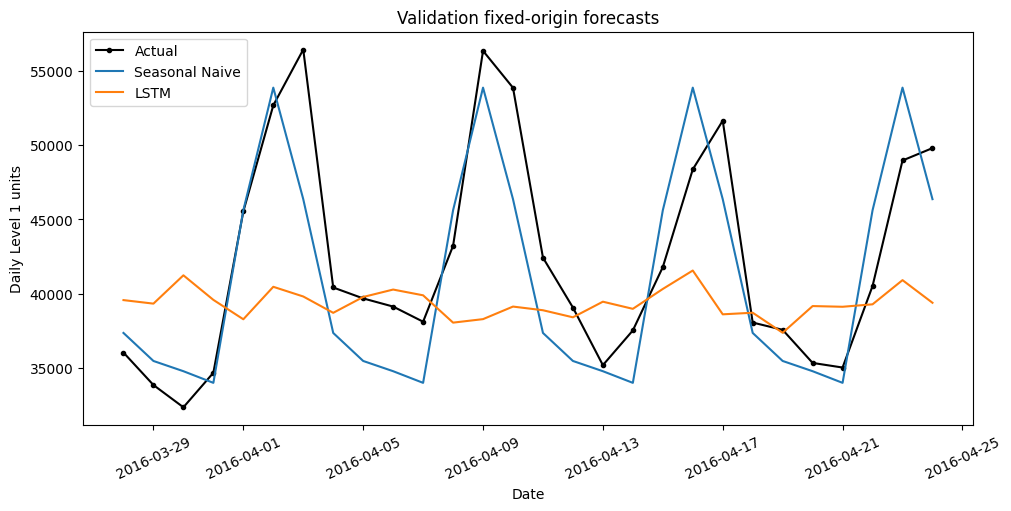

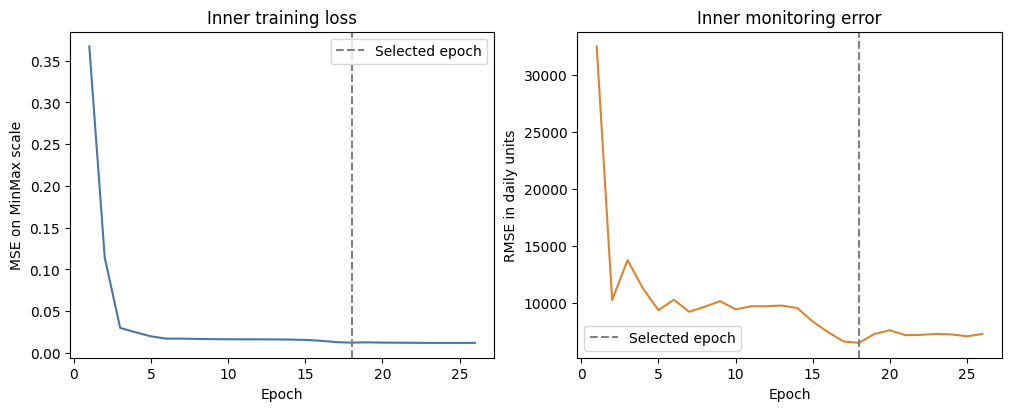

In [8]:
fig_forecast, ax = plt.subplots(figsize=(10, 5), layout='constrained')
actual_val = development.iloc[1885:1913]
ax.plot(actual_val['date'], actual_val['total_sales'], color='black', marker='o', markersize=3, label='Actual')
for cid, label in [('seasonal_naive_7','Seasonal Naive'),(selected_config['config_id'],'LSTM')]:
    subset = cv_predictions[cv_predictions['config_id'].eq(cid) & cv_predictions['fold'].eq(3)]
    ax.plot(pd.to_datetime(subset['date']), subset['prediction'], label=label)
ax.set(title='Validation fixed-origin forecasts', ylabel='Daily Level 1 units', xlabel='Date')
ax.legend()
ax.tick_params(axis='x', rotation=25)
plt.show()

inner = learning_curves[learning_curves['run_id'].eq(best_run[0]['run_id']) &
                        learning_curves['stage'].eq('inner_early_stop')]
fig_learning, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
axes[0].plot(inner['epoch'], inner['train_loss'], color='#4776a8')
axes[0].set(title='Inner training loss', xlabel='Epoch', ylabel=selected_config['loss'].upper()+' on MinMax scale')
axes[1].plot(inner['epoch'], inner['inner_rmse'], color='#d98532')
axes[1].set(title='Inner monitoring error', xlabel='Epoch', ylabel='RMSE in daily units')
for ax in axes:
    ax.axvline(best_run[0]['selected_epoch'], color='gray', linestyle='--', label='Selected epoch')
    ax.legend()
plt.show()

## Save and verify the handoff

The checkpoint contains tensor weights. The JSON manifest specifies the network,
MinMax scale, configuration, seed and selected epochs. The earlier-window
scores reuse the configuration selected on the designated Validation window.

In [9]:
require(len(candidate_search)==8 and len(fit_log)==24 and len(seed_sensitivity)==3,
        'Unexpected number of fits or candidates.')
require(len(cv_scores)==15 and len(cv_predictions)==420, 'Incomplete evaluation.')
require((fit_log['last_training_target_day'] <= fit_log['origin_day']).all(),
        'A fit includes targets beyond its origin.')
inner_fits = fit_log[fit_log['stage'].eq('inner_early_stop')]
require((inner_fits['last_training_target_day']+1 == inner_fits['monitor_first_day']).all(),
        'Inner fitting and monitoring overlap.')
require((inner_fits['monitor_last_day'] == inner_fits['origin_day']).all(),
        'Inner monitoring extends beyond the origin.')
require((cv_predictions['prediction'] >= 0).all(), 'Negative forecast after clipping.')

artifact_dir = output_dir/'04_Outputs_and_Artifacts'
table_dir = artifact_dir/'table'
figure_dir = artifact_dir/'figures'
model_dir = artifact_dir/'models_saved'/'lstm'
prediction_dir = output_dir/'02_Data'/'predictions'
for directory in (table_dir, figure_dir, model_dir, prediction_dir):
    directory.mkdir(parents=True, exist_ok=True)
exported_paths = []
tables = {
    'lstm_candidate_search.csv': candidate_search,
    'lstm_fit_log.csv': fit_log,
    'lstm_cv_scores.csv': cv_scores,
    'lstm_comparison_summary.csv': comparison_summary,
    'lstm_learning_curves.csv': learning_curves,
    'lstm_seed_sensitivity.csv': seed_sensitivity,
}
for name, table in tables.items():
    path = table_dir/name
    table.to_csv(path,index=False)
    exported_paths.append(path)
predictions = {
    'lstm_candidate_predictions.csv': pd.concat(search_forecasts, ignore_index=True),
    'lstm_cv_predictions.csv': cv_predictions,
    'lstm_seed_predictions.csv': pd.concat([r[1] for r in seed_runs], ignore_index=True),
}
for name, table in predictions.items():
    path = prediction_dir/name
    table.to_csv(path,index=False)
    exported_paths.append(path)
for name, figure in [('lstm_validation_forecasts.png',fig_forecast),('lstm_learning_curve.png',fig_learning)]:
    path = figure_dir/name
    figure.savefig(path, dpi=300)
    exported_paths.append(path)

checkpoint = model_dir/'lstm_selected_seed42.pt'
torch.save(best_run[2].state_dict(), checkpoint)
exported_paths.append(checkpoint)
restored = SalesLSTM(selected_config['hidden_size'])
restored.load_state_dict(torch.load(checkpoint, map_location='cpu', weights_only=True))
restored_prediction = np.maximum(
    predict_sales(restored,sales[:1885],selected_config['lookback'],best_run[3]),0.0)
np.testing.assert_allclose(restored_prediction,best_run[1]['prediction'],rtol=1e-9,atol=1e-7)

versions = {k:metadata.version(k) for k in ('numpy','pandas','matplotlib')}
versions['torch'] = str(torch.__version__)
manifest = {
    'configuration': selected_config, 'architecture': {'input_size':1,'num_layers':LAYERS,
        'hidden_size':selected_config['hidden_size'],'dropout':DROPOUT,'head_outputs':HORIZON},
    'input_series':'Level 1 sales history only','horizon':HORIZON,'origins':list(ORIGINS),
    'seed':PRIMARY_SEED,'sensitivity_seeds':list(SENSITIVITY_SEEDS),
    'checkpoint_origin':1885,'checkpoint_minmax':best_run[3],
    'checkpoint_path':checkpoint.relative_to(output_dir).as_posix(),
    'checkpoint_sha256':hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
    'selected_epochs_by_fold':{str(fold):result[0]['selected_epoch'] for fold,result in main_runs.items()},
    'training':{'optimizer':'Adam','learning_rate':LEARNING_RATE,'batch_size':BATCH_SIZE,
                'lr_step':LR_STEP,'lr_gamma':LR_GAMMA,'huber_delta':HUBER_DELTA,
                'max_epochs':MAX_EPOCHS,'patience':PATIENCE,'inner_monitor_days':HORIZON,
                'epoch_rule':'inner minimum RMSE, then fixed-epoch fit on full origin prefix',
                'device':'cpu','threads':CPU_THREADS},
    'versions':versions,'test_labels_read':False,'test_forecasts_computed':False,
}
manifest_path = artifact_dir/'lstm_selected_configuration.json'
manifest_path.write_text(json.dumps(manifest,indent=2),encoding='utf-8')
exported_paths.append(manifest_path)
report = {
    'status':'PASS','created_utc':datetime.now(timezone.utc).isoformat(),
    'python':platform.python_version(),'versions':versions,'files_read':list(FILENAMES),
    'data_fingerprints':{row['file']:row['table_sha256'] for row in input_inventory},
    'test_labels_read':False,'test_forecasts_computed':False,'candidate_count':len(candidate_search),
    'fit_count':len(fit_log),'cv_score_rows':len(cv_scores),'cv_forecast_rows':len(cv_predictions),
    'seed_runs':len(seed_sensitivity),'checkpoint_reload_matches':True,
    'comparison':comparison_summary.to_dict('records'),
    'validation_seed_rmsse':{str(row.seed):row.rmsse for row in seed_sensitivity.itertuples()},
    'elapsed_seconds_before_packaging':perf_counter()-RUN_STARTED,
    'files':[path.relative_to(output_dir).as_posix() for path in exported_paths],
}
report_path = artifact_dir/'lstm_run_report.json'
report_path.write_text(json.dumps(report,indent=2),encoding='utf-8')
exported_paths.append(report_path)

zip_path = output_dir/'08_lstm_results.zip'
with ZipFile(zip_path,'w',compression=ZIP_DEFLATED) as archive:
    for path in exported_paths:
        archive.write(path,path.relative_to(output_dir).as_posix())
with ZipFile(zip_path) as archive:
    require(len(archive.namelist())==14 and archive.testzip() is None,'Incomplete results archive.')
print('LSTM CHECK PASSED')
print(f'Candidates {len(candidate_search)} | fits {len(fit_log)} | CV forecasts {len(cv_predictions)}')
print(f'Selected {selected_config["config_id"]} | Validation RMSSE {best_run[0]["rmsse"]:.6f}')
print(f'Download {zip_path}')

LSTM CHECK PASSED
Candidates 8 | fits 24 | CV forecasts 420
Selected lstm_w28_h32_mse | Validation RMSSE 1.301320
Download /kaggle/working/08_lstm_results.zip


## References

- [PyTorch LSTM](https://docs.pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
- [PyTorch model state and checkpoint loading](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)